# 1.4 Image classification with a CNN: is this document a CV?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jauniusc/cvmatch/blob/main/1.4/1_4_documents_cnn.ipynb)

Task 1.4. Based on the lecturer's notebook **`cnn.ipynb`** (A. Laukaitis), which trains a CNN on CIFAR-10.
First I explain how the original works, then I redo it with my own document image dataset for my **CVMatch AI** project.

## How the original notebook works

**Part 1: CNN on CIFAR-10**
1. Loads **CIFAR-10**: 50,000 training and 10,000 test images, 32×32 pixels, RGB, 10 classes (airplane, cat, ship...).
   The Keras download was very slow, so it is loaded from Hugging Face (`uoft-cs/cifar10`).
2. Pixel values are divided by 255, so they are between 0 and 1 (neural networks learn better with small numbers).
3. Shows the first 100 images with their labels to check the data.
4. **Model:** `Conv2D(32, 3×3)` → `MaxPooling2D(2×2)` → `Conv2D(64)` → `MaxPooling2D` → `Conv2D(64)` → `Flatten` → `Dense(64)` → `Dense(10)`.
   - A `Conv2D` layer slides small 3×3 filters over the image and finds simple patterns (edges, lines), deeper layers find more complex shapes.
   - `MaxPooling` keeps the biggest value from every 2×2 block, so the image gets 2× smaller.
   - `Dense(10)` gives one score (logit) per class.
   - Parameters per filter = 3·3·(input channels) + 1 bias. The model has 122,570 parameters.
5. Loss is `SparseCategoricalCrossentropy(from_logits=True)`: "sparse" because labels are numbers 0–9 (not one-hot vectors).
6. Trains 20 epochs. Train accuracy goes to ~87% but test accuracy stays at **~70%**, so the model overfits.
   (The test set is also used as validation data here.)

**Part 2: Filters and feature maps**
7. Takes the weights of the first `Conv2D` layer and shows the 3×3 filters as small grey images (one per colour channel).
8. Builds a model that stops after the first layer and shows the **feature maps** for one image: each filter highlights different parts.
9. Computes one feature map **by hand with NumPy**: slides the 3×3×3 filter over the image, multiplies and sums, adds the bias and applies ReLU.
   The result is the same as the Keras feature map, so this shows exactly what a convolution does.

**Part 3: Multilayer perceptron (MLP)**
10. Same data with a plain network: `Flatten` → `Dense(32)` → `Dense(64)` → `Dense(64)` → `Dense(10)`.
    It only gets **~43%**, because after `Flatten` the network doesn't know which pixels are next to each other.

## My data: CVs and other documents

My project **CVMatch AI** compares a CV with a job ad. In real life people upload all kinds of files, so a first useful step is to check
**if the uploaded scan is a CV at all**, or some other document. So I made a small dataset with 4 types of documents that can come with a job application:

| Class | What it is |
|---|---|
| `resume` | CV / resume |
| `letter` | letter (e.g. cover letter) |
| `email` | printed email |
| `form` | filled form |

The images come from **RVL-CDIP** (Harley et al., 2015), a public dataset of 400,000 scanned documents in 16 classes.
I took 1,000 scans per class from the Hugging Face copy (`chainyo/rvl-cdip`), shrank them to **128×128 greyscale**
and saved them in `data/documents/` as `train` (700 per class), `val` (150) and `test` (150).
The script is `scripts/prepare_documents_dataset.py`.

This is harder than CIFAR-10 in one way: at 128×128 the text can't be read, so the model can only use the **layout**
(where the text blocks, lines and empty space are). A CV usually has short lines and sections, a letter has a header and paragraphs,
an email has a header block at the top, a form has boxes and lines.

What I changed: the data loading, the input shape (128×128 instead of 32×32), 4 classes instead of 10, and validation data separate from test.
The models are the same as in the original.

---
# PART 1
### Load and prepare my document dataset

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

tf.keras.utils.set_random_seed(42)

In [2]:
import os
import numpy as np
from PIL import Image

# Locally the images are in the repo. In Colab the repo is cloned first.
if os.path.exists('../data/documents'):
  data_dir = '../data/documents'
else:
  !git clone -q https://github.com/jauniusc/cvmatch.git
  data_dir = 'cvmatch/data/documents'

class_names = ['resume', 'letter', 'email', 'form']

def load_folder(split):
  images, labels = [], []
  for label, name in enumerate(class_names):
    folder = os.path.join(data_dir, split, name)
    for file in sorted(os.listdir(folder)):
      img = Image.open(os.path.join(folder, file)).convert('RGB')   # greyscale scan -> 3 channels
      images.append(np.array(img))
      labels.append(label)
  images = np.array(images).astype('float32') / 255.0   # normalize to 0..1
  labels = np.array(labels).reshape(-1, 1)
  order = np.random.RandomState(42).permutation(len(images))   # the files are sorted by class, so shuffle them
  return images[order], labels[order]

train_images, train_labels = load_folder('train')
val_images, val_labels = load_folder('val')
test_images, test_labels = load_folder('test')

print(train_images.shape, val_images.shape, test_images.shape)
print('Images per class (train):', np.bincount(train_labels[:, 0]))

(2800, 128, 128, 3) (600, 128, 128, 3) (600, 128, 128, 3)
Images per class (train): [700 700 700 700]


### Let's plot the first 25 images

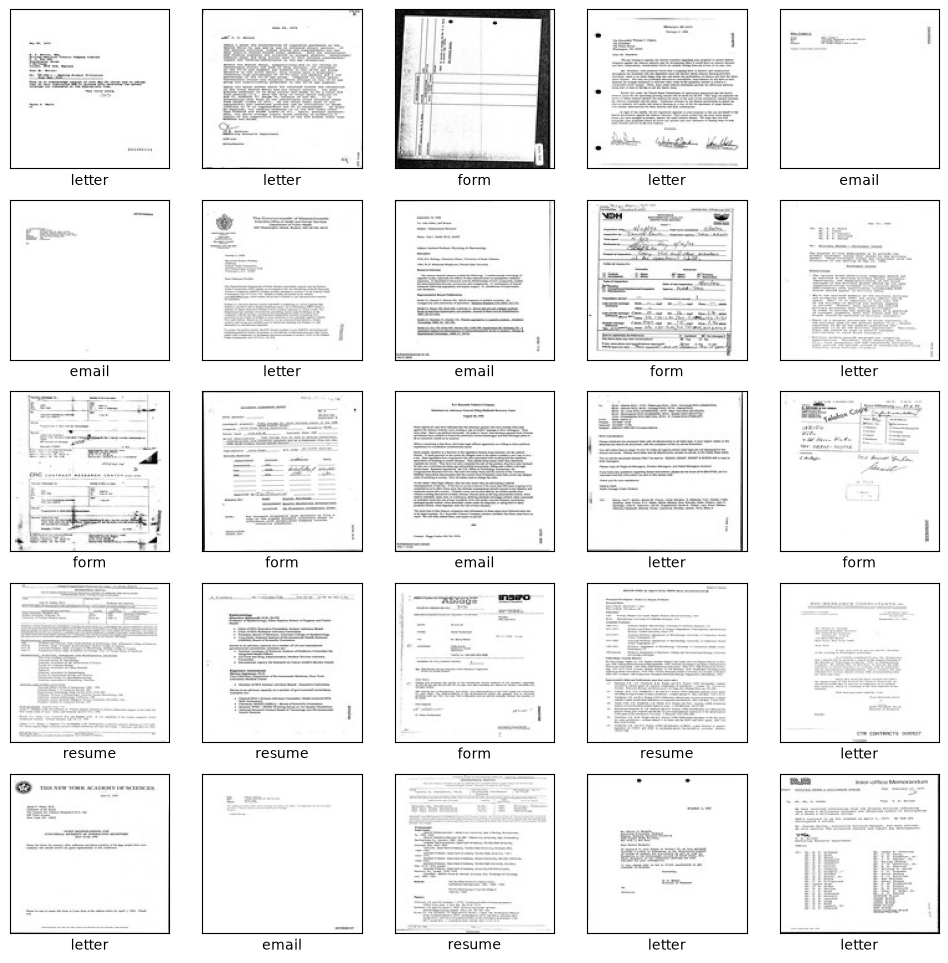

In [3]:
plt.figure(figsize=(12, 12))
for i in range(25):
  plt.subplot(5, 5, i + 1)
  plt.xticks([]); plt.yticks([]); plt.grid(False)
  plt.imshow(train_images[i])
  plt.xlabel(class_names[train_labels[i][0]])
plt.show()

---
# Convolutional Neural Network
### Step 2. Model
Same layers as the original, only the input is 128×128×3 and the output has 4 classes.

In [4]:
model = models.Sequential()
model.add(layers.Input(shape=(128, 128, 3)))
model.add(layers.Conv2D(32, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(len(class_names)))

model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     3,211,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,267,908 (12.47 MB)

 Trainable params: 3,267,908 (12.47 MB)

 Non-trainable params: 0 (0.00 B)

The model has many more parameters than the CIFAR-10 one (~3.3 million instead of 122 thousand) because the images are bigger:
after the last conv layer the feature map is 28×28×64 instead of 4×4×64, so `Flatten` gives 50,176 values
and almost all parameters are in the first `Dense` layer. With only 2,800 training images this will probably overfit.

### Step 3. Train and evaluate the model

In [5]:
history = model.fit(train_images, train_labels, epochs=20,
                    validation_data=(val_images, val_labels), verbose=2)

Epoch 1/20


88/88 - 15s - 171ms/step - accuracy: 0.5050 - loss: 1.1221 - val_accuracy: 0.7183 - val_loss: 0.8289


Epoch 2/20


88/88 - 11s - 128ms/step - accuracy: 0.7489 - loss: 0.6852 - val_accuracy: 0.7567 - val_loss: 0.7017


Epoch 3/20


...

88/88 - 17s - 188ms/step - accuracy: 1.0000 - loss: 2.6995e-04 - val_accuracy: 0.8000 - val_loss: 1.9627


Epoch 19/20


88/88 - 16s - 180ms/step - accuracy: 1.0000 - loss: 1.8376e-04 - val_accuracy: 0.8050 - val_loss: 1.9948


Epoch 20/20


88/88 - 16s - 183ms/step - accuracy: 1.0000 - loss: 1.4511e-04 - val_accuracy: 0.8017 - val_loss: 2.0306


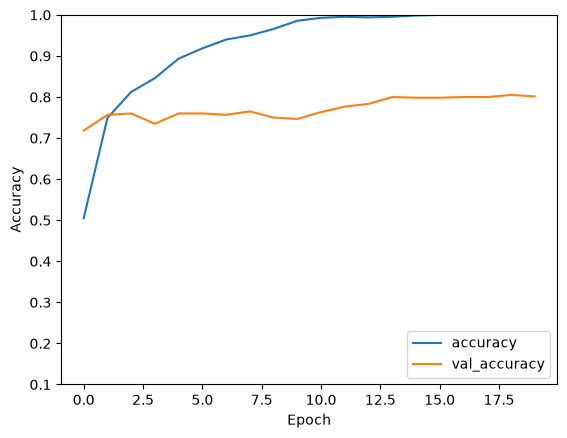

19/19 - 1s - 49ms/step - accuracy: 0.8133 - loss: 1.4830


CNN test accuracy: 0.8133333325386047


In [6]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy')
plt.ylim([0.1, 1]); plt.legend(loc='lower right')
plt.show()

test_loss, cnn_test_acc = model.evaluate(test_images, test_labels, verbose=2)
print("CNN test accuracy:", cnn_test_acc)

### Which classes get mixed up?

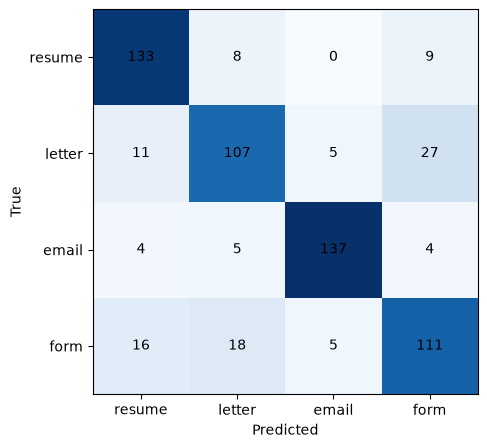

[[133   8   0   9]
 [ 11 107   5  27]
 [  4   5 137   4]
 [ 16  18   5 111]]
CV vs not-CV accuracy: 0.92


In [7]:
predictions = np.argmax(model.predict(test_images, verbose=0), axis=1)
confusion = tf.math.confusion_matrix(test_labels[:, 0], predictions).numpy()

plt.figure(figsize=(5, 5))
plt.imshow(confusion, cmap='Blues')
plt.xticks(range(4), class_names); plt.yticks(range(4), class_names)
plt.xlabel('Predicted'); plt.ylabel('True')
for i in range(4):
  for j in range(4):
    plt.text(j, i, confusion[i, j], ha='center', va='center')
plt.show()
print(confusion)

# For CVMatch the important question is: "is it a CV or not?"
is_cv_true = test_labels[:, 0] == 0
is_cv_pred = predictions == 0
print("CV vs not-CV accuracy:", np.mean(is_cv_true == is_cv_pred))

---
# PART 2
### Visualizing filters and feature maps
The first `Conv2D` layer has 32 filters of size 3×3×3. Here are the first 2 filters, each colour channel separately.
(My images are greyscale, so all 3 channels of the input are the same, but the filters still learn different weights for them.)

(3, 3, 3, 32)


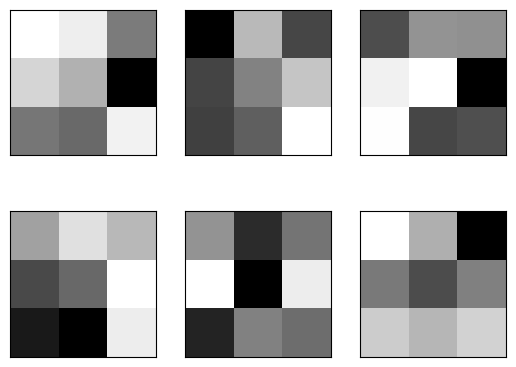

In [8]:
filters, biases = model.layers[0].get_weights()
print(filters.shape)

ix = 1
for filter_i in range(2):
  filter_tmp = filters[:, :, :, filter_i]
  for channel_j in range(3):
    ax = plt.subplot(2, 3, ix)
    ax.set_xticks([]); ax.set_yticks([])
    plt.imshow(filter_tmp[:, :, channel_j], cmap='gray')
    ix += 1
plt.show()

### Feature maps of the first layer for one CV

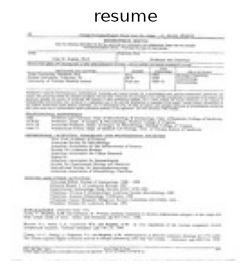

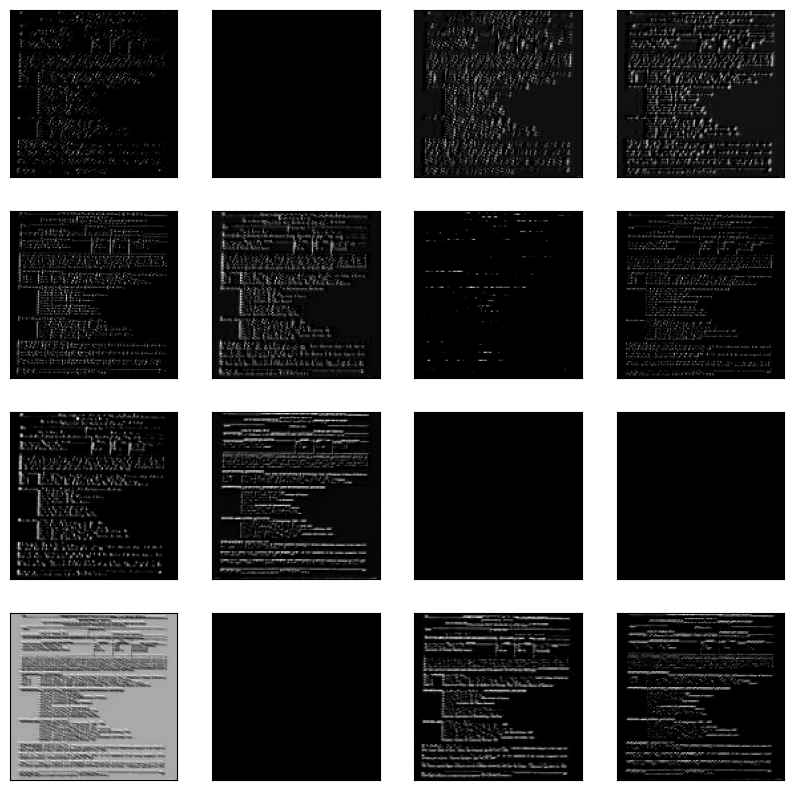

In [9]:
model_layers_0 = tf.keras.Model(inputs=model.inputs, outputs=model.layers[0].output)

img_index = int(np.where(train_labels[:, 0] == 0)[0][0])   # the first resume in the training set
img = np.expand_dims(train_images[img_index], axis=0)
feature_maps = model_layers_0.predict(img, verbose=0)

plt.figure(figsize=(3, 3)); plt.imshow(train_images[img_index]); plt.axis('off')
plt.title(class_names[train_labels[img_index][0]]); plt.show()

plt.figure(figsize=(10, 10))
for ix in range(1, 17):
  ax = plt.subplot(4, 4, ix)
  ax.set_xticks([]); ax.set_yticks([])
  plt.imshow(feature_maps[0, :, :, ix - 1], cmap='gray')
plt.show()

### Doing the convolution by hand with NumPy
Take filter number 2 and slide it over the image: at every position multiply the 3×3×3 piece of the image with the filter,
sum everything, add the bias and apply ReLU (negative values → 0). It should give the same picture as Keras.

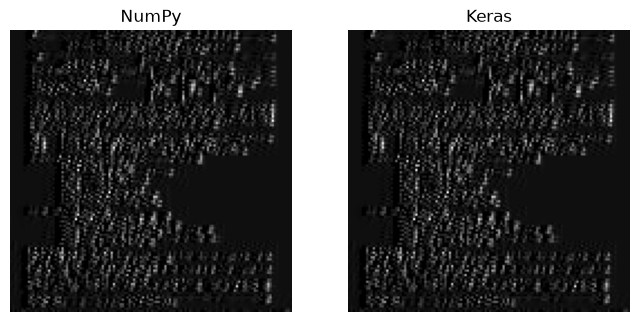

Max difference between NumPy and Keras: 1.043081283569336e-07


In [10]:
input_image = train_images[img_index]
filter = filters[:, :, :, 2]
bias = biases[2]

feature_map = np.zeros((input_image.shape[0] - filter.shape[0] + 1,
                        input_image.shape[1] - filter.shape[1] + 1))

for i in range(feature_map.shape[0]):
  for j in range(feature_map.shape[1]):
    feature_map[i, j] = np.sum(input_image[i:i + 3, j:j + 3, :] * filter) + bias

feature_map[feature_map < 0] = 0   # ReLU

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1); plt.imshow(feature_map, cmap='gray'); plt.title('NumPy'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(feature_maps[0, :, :, 2], cmap='gray'); plt.title('Keras'); plt.axis('off')
plt.show()

print("Max difference between NumPy and Keras:", np.abs(feature_map - feature_maps[0, :, :, 2]).max())

---
# PART 3. Image classification with a Multilayer Perceptron
Same MLP as in the original, only the input is 128×128×3 and the output has 4 classes.

In [11]:
mlp = models.Sequential()
mlp.add(layers.Input(shape=(128, 128, 3)))
mlp.add(layers.Flatten())
mlp.add(layers.Dense(32, activation='relu'))
mlp.add(layers.Dense(64, activation='relu'))
mlp.add(layers.Dense(64, activation='relu'))
mlp.add(layers.Dense(len(class_names)))

mlp.compile(optimizer='adam',
            loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
            metrics=['accuracy'])
mlp.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │     1,572,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,579,428 (6.03 MB)

 Trainable params: 1,579,428 (6.03 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
history_mlp = mlp.fit(train_images, train_labels, epochs=15,
                      validation_data=(val_images, val_labels), verbose=2)

Epoch 1/15


88/88 - 1s - 14ms/step - accuracy: 0.2493 - loss: 2.0332 - val_accuracy: 0.2500 - val_loss: 1.3864


Epoch 2/15


88/88 - 1s - 7ms/step - accuracy: 0.2464 - loss: 1.3866 - val_accuracy: 0.2500 - val_loss: 1.3863


Epoch 3/15


...

88/88 - 0s - 5ms/step - accuracy: 0.2343 - loss: 1.3865 - val_accuracy: 0.2500 - val_loss: 1.3863


Epoch 14/15


88/88 - 0s - 5ms/step - accuracy: 0.2343 - loss: 1.3865 - val_accuracy: 0.2500 - val_loss: 1.3863


Epoch 15/15


88/88 - 1s - 6ms/step - accuracy: 0.2343 - loss: 1.3865 - val_accuracy: 0.2500 - val_loss: 1.3863


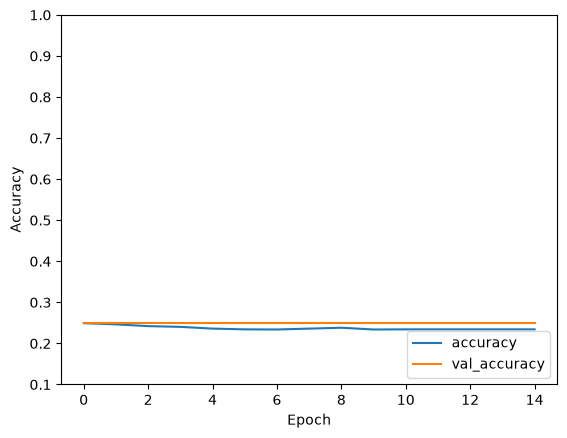

19/19 - 0s - 2ms/step - accuracy: 0.2500 - loss: 1.3863


MLP test accuracy: 0.25
CNN test accuracy: 0.8133333325386047


In [13]:
plt.plot(history_mlp.history['accuracy'], label='accuracy')
plt.plot(history_mlp.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy')
plt.ylim([0.1, 1]); plt.legend(loc='lower right')
plt.show()

test_loss, mlp_test_acc = mlp.evaluate(test_images, test_labels, verbose=2)
print("MLP test accuracy:", mlp_test_acc)
print("CNN test accuracy:", cnn_test_acc)

---
## Results and conclusions

| Model | Test accuracy |
|---|---|
| MLP | 0.25 |
| **CNN** | **0.813** |

- The CNN is much better than the MLP, like in the original. The MLP didn't learn at all (25% = random guessing with 4 classes):
  after `Flatten` it doesn't know which pixels are next to each other, and for documents the layout is the most important thing.
- For CVMatch the main question is "CV or not CV?", and the CNN answers it correctly for **92%** of the test scans.
- Letters and forms get mixed up most, CVs and emails are the easiest.
- The model overfits: 100% on the training data, but ~0.80 on validation (3.3 million parameters, only 2,800 training images).
- The convolution done by hand with NumPy gives the same feature map as Keras.